# Drift Diffusion Model (DDM) analysis for TOJ task
**List of contents:**\
1- DDM Model based on Prior Response\
2- DDM Model based on Prior Stimulus\
3- DDM for general data

This script fits a DDM model using PyDDM for each participant,SOA condition, and prior response condition.\
The goal is to estimate the following parameters:
- drift rate (v)
- noise (σ)
- starting point (z)
- non-decision time (t0)

Model fit is evaluated by comparing predicted vs observed:
- RT quantiles (20%, 50%, 80%)
- accuracy

In [1]:
import pyddm
from pyddm import Sample
import pyddm.plot
import matplotlib.pyplot as plt
import pandas as pd
from pyddm.models import LossRobustLikelihood, LossLikelihood
import os
import numpy as np
from scipy.stats import pearsonr, spearmanr

###############################################################\
###############################################################
# 1- DDM Model based on Prior Response
**List of contents:**\
1-1 Fitting DDM\
1-2 Investigating fits and exclusions\
1-3 Cross-Validation

In [2]:
df = pd.read_excel("files/TOJ_prior_response_data.xlsx")

In [3]:
df['resp_num'] = df['resp'].map({'v': 1, 'a': 0})

In [4]:
df

,participant,pre_resp,SOA,resp,rt,resp_num
0,1,a,-400,a,1.454046,0
1,1,a,-400,a,1.504481,0
2,1,a,-400,a,1.069864,0
3,1,a,-400,a,1.387248,0
4,1,a,-300,a,0.852489,0
...,...,...,...,...,...,...
11199,22,v,400,v,0.735595,1
11200,22,v,400,v,0.719036,1
11201,22,v,400,v,0.735575,1
11202,22,v,400,v,0.602115,1


###############################################################
## 1-1 Fitting DDM

In [4]:
# Fit a DDM separately for each participant,
# prior response condition, and SOA.

# Boundary is fixed to 1 for model identifiability.

# DataFrame to store the final results
params = pd.DataFrame()

# List of participants
participants = df['participant'].unique()

# List of previous responses (pre_resp)
pre_resps = df['pre_resp'].unique()

# List of SOAs available in the participant's data
SOAs = df['SOA'].unique()

# Loop over each participant
for participant in participants:
    # Filter data for the specific participant
    d = df[df['participant'] == participant]
    print(participant)
    # Loop over each pre_resp
    for pre_resp in pre_resps:
        # Filter data based on pre_resp
        d_pre_resp = d[d['pre_resp'] == pre_resp]

        # Loop over each SOA
        for soa in SOAs:
            # Filter data for the specific SOA
            d_soa = d_pre_resp[d_pre_resp['SOA'] == soa]


            # Fit the DDM model with variable noise and fixed boundary = 1
            model = pyddm.gddm(drift="d",
                               noise="noise",  # noise as a free parameter
                               bound=1.0,      # fix boundary at 1
                               nondecision='t0', 
                               starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # parameters to be fitted
                               T_dur=d_soa['rt'].max() + 0.01)

            # Prepare data for the model
            data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

            # Fit the model to the data
            model.fit(
                sample=data, 
                lossfunction=LossRobustLikelihood, 
                verbose=False
            )


            # Extract fitted parameters
            p = model.parameters()

            # Create a DataFrame to store results for this combination of pre_resp, SOA, and participant
            pp = pd.DataFrame({
                'participant': [participant],
                'pre_resp': [pre_resp],  # add pre_resp to the results
                'SOA': [soa],
                'drift': [p['drift']['drift']],
                'noise': [p['noise']['noise']],  # store noise as a fitted parameter
                'bound': [1.0],  # fixed boundary value
                'Z': [p['IC']['x0']],
                't0': [p['overlay']['nondectime']]
            })

            # Append results to the final DataFrame
            params = pd.concat([params, pp], ignore_index=True)

1


Info: Params [-1.17447938  0.1836824   0.59008587  0.00206018] gave -1.1213104881070235
Info: Params [-8.55816401e-01  1.95763391e-01  1.34113588e-01  5.89853477e-04] gave 0.7899485773685455
Info: Params [-0.33442266  0.81413955 -0.38230289  0.83297757] gave 19.0673560156211
Info: Params [-0.32235201  0.80553765 -0.45900571  0.79238292] gave 17.82532894689932
Info: Params [-0.36016951  0.92674015  0.19958189  1.04429256] gave 14.240968119427958
Info: Params [-0.30822008  0.51786149 -0.74342594  0.90528243] gave 6.7027853630040655
Info: Params [ 0.06723653  0.74467088 -0.43535428  0.62753342] gave 17.041788141679582
Info: Params [ 0.01653209  0.63759426 -0.43355883  0.58160401] gave 20.778950962876795
Info: Params [-0.32544136  0.77585185 -0.26476362  0.59009699] gave 18.86081788181351
Info: Params [ 0.76647307  1.23111711 -0.7214154   1.59577979] gave 14.804488982954101
Info: Params [-0.16246563  0.9483313  -0.41871012  0.81959696] gave 22.66298515387159
Info: Params [ 0.08613462  1.18

3


Info: Params [-1.20539148  0.17269901  0.51552478  0.00214823] gave -3.233971282126982
Info: Params [-0.61485844  0.32133022  0.17432014  0.03026521] gave 11.115372692559008
Info: Params [-0.46679366  1.12713162  0.10698125  0.9259676 ] gave 14.892620494691116
Info: Params [ 0.34536209  0.98830684 -0.45529766  1.0775376 ] gave 16.9667270382854
Info: Params [0.10063201 0.9036728  0.10518067 0.8616658 ] gave 23.201216780511313
Info: Params [-0.36341555  0.8838157   0.49220225  0.97578635] gave 20.263582584546675
Info: Params [-0.2531501   0.6842524   0.00349869  0.52013829] gave 31.194190920932307
Info: Params [-0.46606373  1.13816158  0.15299325  1.04220475] gave 18.493517380803855
Info: Params [-0.09065171  0.80472611  0.37271053  0.82163444] gave 28.884018064175724
Info: Params [-0.06711826  0.85866419  0.49176772  1.61015053] gave 15.936858289453554
Info: Params [-0.0037175   0.83408402  0.29552396  0.89383575] gave 26.47456677510398
Info: Params [ 0.05837192  1.06473717 -0.19401084 

5


Info: Params [-2.08436168  0.3123998   0.78193999  0.01657835] gave -6.71155932289041
Info: Params [-1.22900694  0.39500121 -0.26448312  0.23590053] gave -0.7700887487216053
Info: Params [-0.61811822  0.93362478 -0.55903704  0.6271096 ] gave 4.950154945906425
Info: Params [-0.30230237  0.54513225 -0.74918139  0.60719003] gave 7.859794998404695
Info: Params [ 0.02193999  0.89082986 -0.01875809  0.61984986] gave 22.291584387314902
Info: Params [ 0.19224847  0.98542996 -0.18445897  0.79550527] gave 19.3966128018473
Info: Params [-0.24021198  0.6802492   0.71689536  0.71316193] gave 9.062055972861877
Info: Params [ 0.26960147  1.1737001  -0.0679298   0.63253812] gave 14.841722826659945
Info: Params [0.02973994 0.81685102 0.52248276 0.60952916] gave 18.317127871899647
Info: Params [3.92657345 1.38452304 0.36400906 0.66365376] gave -3.651765497188731
Info: Params [0.41375111 0.88963247 0.19008045 0.50909813] gave 14.03601599068415
Info: Params [-0.13633687  0.79602791  0.11263676  0.43294361

... (82 outputs left out)

Info: Params [0.20659598 0.74105482 0.38950529 0.76285625] gave 20.298661636187262
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-0.01702206  0.7513996   0.04030412  0.5350834 ] gave 26.889845596748266
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

Info: Params [0.14474375 0.64163684 0.20995289 0.58891854] gave 35.36999272107234
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-0.05922277  0.77184993 -0.28640859  1.14706943] gave 26.48352306097982
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from 

Info: Params [ 0.49743473  0.50617602 -0.26318078  0.26998739] gave 22.895131661690918
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [0.47355407 0.63614288 0.21829767 0.43241141] gave 29.497854286119818
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\2280267367.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

     participant pre_resp  SOA     drift     noise  bound         Z        t0
0              2        a  200  5.000000  1.550168    1.0 -0.795865  0.668788
1              2        a  -80  1.109341  1.068183    1.0 -0.648842  0.525495
2              2        a    0  0.048640  1.323686    1.0 -0.296964  0.500014
3              2        a -150 -1.351982  1.565522    1.0 -0.136337  0.580354
4              2        a  120 -1.538072  1.047148    1.0  0.603159  0.655956
..           ...      ...  ...       ...       ...    ...       ...       ...
915           21        v  -80  0.919131  0.916190    1.0 -0.414152  1.213172
916           21        v -400 -1.418600  0.228074    1.0  0.767638  0.005096
917           21        v -100  0.084418  0.749209    1.0 -0.230933  0.822297
918           21        v  150  0.670411  0.679238    1.0 -0.163697  0.722084
919           21        v    0  0.157530  0.864300    1.0 -0.280382  1.560163

[920 rows x 8 columns]


In [5]:
params.to_excel("files/TOJ_prior_response_DDM_parameters.xlsx", index=False)

###############################################################
## 1-2 Investigating fits and exclusions

In [5]:
# calculate predicted and observed statistics

data_list = []
model_list = []

# Group empirically observed dataset by experimental factors
groups = df.groupby(['participant', 'SOA', 'pre_resp'])

for (participant, soa, pre_resp), d in groups:
    # 1. Calculate empirical RT quantiles and visual-first choice probability
    p_obs = {
        'participant': participant,
        'SOA': soa,
        'pre_resp': pre_resp,
        'q1': d['rt'].quantile(.2),
        'q2': d['rt'].quantile(.5),
        'q3': d['rt'].quantile(.8),
        'p_vis': d['resp_num'].mean()
    }
    data_list.append(p_obs)

    # 2. Extract corresponding fitted parameters safely
    p = params[(params['participant'] == participant) & 
               (params['SOA'] == soa) & 
               (params['pre_resp'] == pre_resp)].reset_index(drop=True)


    # Map parameter column names dynamically (handles uppercase/lowercase variations)
    drift_val = float(p['drift'][0])
    noise_val = float(p['noise'][0])
    t0_val = float(p['t0'][0])
    z_val = float(p['Z'][0])

    # 3. Solve PyDDM Model

    model = pyddm.gddm(
        drift=drift_val,
        noise=noise_val,
        bound=1.0,
        nondecision=t0_val, 
        starting_position=min(max(z_val,-.99),.99),
        T_dur=10, dt=.0001, dx=.0001
    )
    s = model.solve()

    # 4. Store predictions
    p_pred = {
        'participant': participant,
        'SOA': soa,
        'pre_resp': pre_resp,
        'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
        'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
        'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
        'p_vis': s.prob('correct')
    }
    model_list.append(p_pred)
        

# Convert lists to DataFrames
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)

In [6]:
# investigate the exclutions

val = 'q1'
r1 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
print(sum(~r1))
val = 'q2'
r2 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r1,r2)
print(sum(~r2))
val = 'q3'
r3 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r,r3)
print(sum(~r3))
val = 'p_vis'
r4 = (model_[val] >= data_[val]-.1) & (model_[val] <= data_[val]+.1)
r = np.logical_and(r,r4)
print(sum(~r4))

8
8
5
4


In [7]:
sum(~r)

24

In [8]:
data_[~r]

,participant,SOA,pre_resp,q1,q2,q3,p_vis
28,1,60,a,1.490933,1.771492,2.493303,0.625000
96,5,-250,a,0.819334,0.952830,1.002903,0.090909
98,5,-200,a,0.705538,1.487512,1.992227,0.000000
119,5,40,v,0.745490,1.871749,2.082269,0.823529
159,6,-20,v,1.393956,3.041642,3.686597,0.600000
170,6,100,a,1.470801,1.821949,2.640506,0.818182
180,6,300,a,1.243647,1.428925,2.446574,0.666667
209,7,20,v,0.531815,1.078395,2.469963,0.650000
288,9,-100,a,1.149797,1.838386,2.269414,0.555556
304,9,60,a,0.609174,1.412447,1.908653,0.750000


In [10]:
params[r].reset_index(drop=True).to_excel("files/TOJ_prior_response_DDM_parameters_clean.xlsx", index=False)

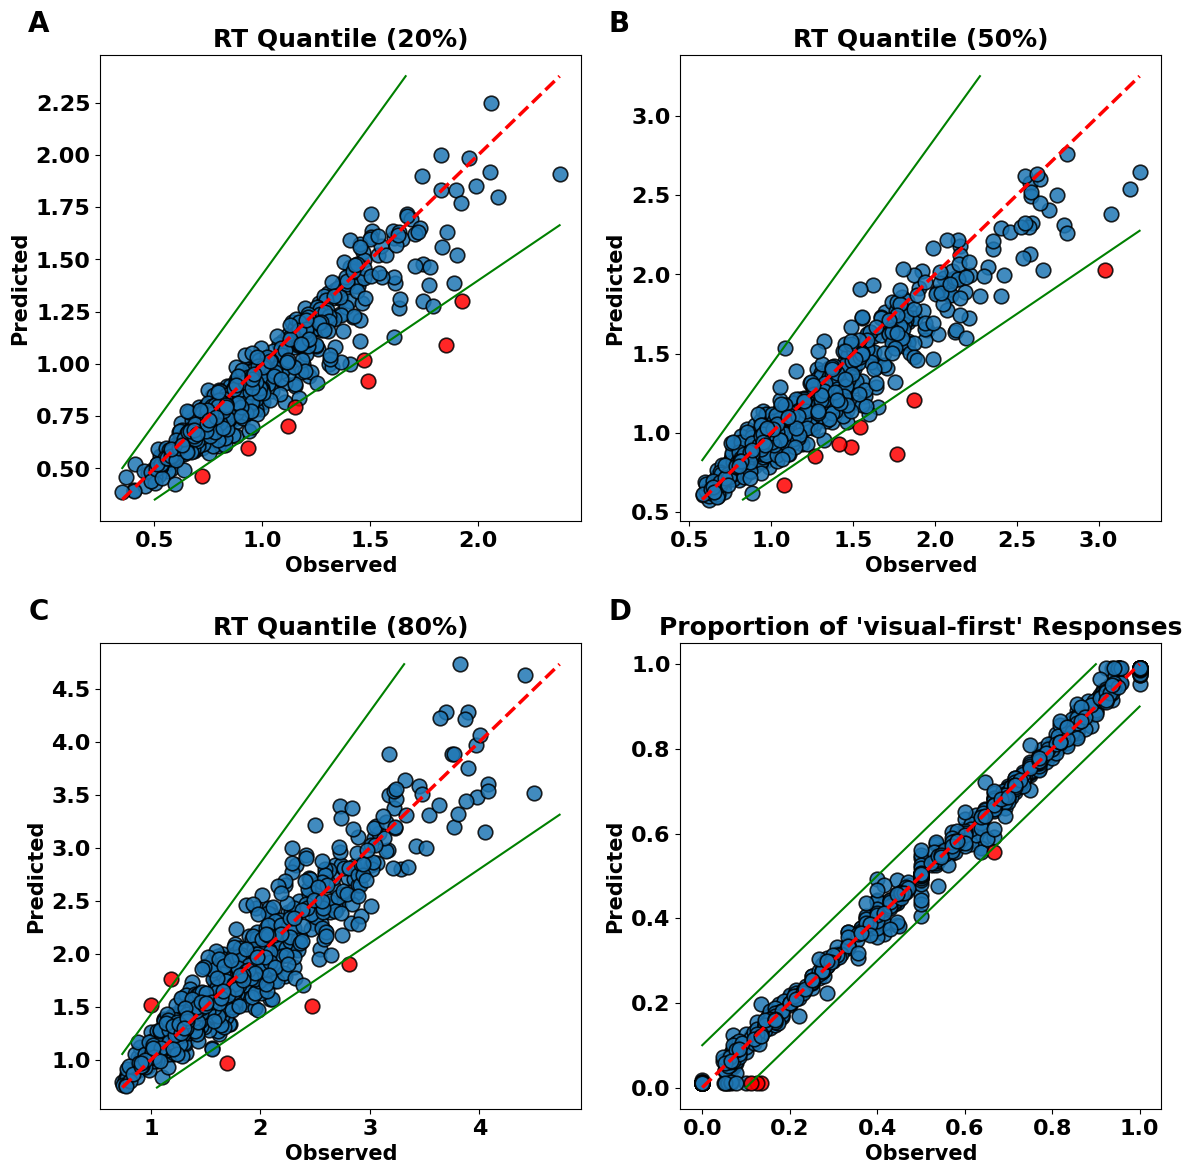

In [11]:
# Configure publication-ready figure formatting parameters
plt.rcParams.update({
    "font.size": 16,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Define diagnostic dimensions (Panel D title updated to reflect accurate psychophysical measure)
plots = [
    (data_['q1'], model_['q1'], "RT Quantile (20%)"),
    (data_['q2'], model_['q2'], "RT Quantile (50%)"),
    (data_['q3'], model_['q3'], "RT Quantile (80%)"),
    (data_['p_vis'], model_['p_vis'], "Proportion of 'visual-first' Responses")
]

panel_labels = ["A", "B", "C", "D"]
R = [r1,r2,r3,r4]
# Iterate over grid cells and plot empirical vs. predicted measures
for i, ax, (x, y, title), label in zip(np.arange(4), axes.flatten(), plots, panel_labels):

    # Render individual participant-SOA data points
    ax.scatter(x[r], y[r],
               s=110,
               edgecolor="black",
               linewidth=1.2,
               alpha=0.85)
    ax.scatter(x[~R[i]], y[~R[i]],
               s=110,
               edgecolor="black",
               c='red',
               linewidth=1.2,
               alpha=0.85)

    # Plot the diagonal line of identity (y = x) representing perfect generative fit
    min_val = min(min(x.dropna()), min(y.dropna()))
    max_val = max(max(x.dropna()), max(y.dropna()))
    ax.plot([min_val, max_val], [min_val, max_val],
            color="red",
            linestyle='--',
            linewidth=2.5)
    if title=="Proportion of 'visual-first' Responses":
        ax.plot([.1, 1], [0, .9],
                color="green",
                linewidth=1.5)
        ax.plot([0, .9], [.1, 1],
                color="green",
                linewidth=1.5)
    else:
        ax.plot([1/.7*min_val, max_val], [min_val, .7*max_val],
                color="green",
                linewidth=1.5)
        ax.plot([min_val, .7*max_val], [1/.7*min_val, max_val],
                color="green",
                linewidth=1.5)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlabel("Observed", fontsize=15)
    ax.set_ylabel("Predicted", fontsize=15)

    # Add panel identification labels (A-D)
    ax.text(-0.15, 1.05, label,
            transform=ax.transAxes,
            fontsize=20,
            fontweight="bold")

plt.tight_layout()

# Save vector PDF for manuscript integration and OSF repository
plt.savefig("files3/TOJ_prior_response_DDMfits.pdf",
            format="pdf",
            bbox_inches="tight")

plt.show()
plt.close()

###############################################################
## 1-3 Cross-Validation

Objective: \
This script executes an out-of-sample predictive cross-validation analysis to evaluate model ability to detect individual differences and generalizability and rule out potential overfitting in the TOJ paradigm. For each unique cell (Participant × Prior Response × SOA), trials are split into independent training (odd-indexed) and testing (even-indexed) subsets. The boundaries represent orthogonal temporal alternatives: Upper (1) for 'visual-first' (v) and Lower (0) for 'auditory-first' (a).Parameters are optimized via MLE on the training subset, and the predictive RT and choice statistics are validated against the held-out empirical testing set.

In [9]:
# split-half the data

current_df = df
current_df['trial_index'] = current_df.groupby(['participant', 'pre_resp', 'SOA']).cumcount()
df_odd = current_df[current_df['trial_index'] % 2 != 0].copy()   # Training Set (Odd trials)
df_even = current_df[current_df['trial_index'] % 2 == 0].copy()  # Testing Set (Even trials)

In [10]:
# fit the model on odd trials and calculate predictive and observed statistics

data_list = []
model_list = []

participants = current_df['participant'].unique()
pre_resps = current_df['pre_resp'].unique()
SOAs = current_df['SOA'].unique()

# Nested loops to isolate each model fitting cell independently
for participant in participants:
    print(participant)
    d_odd_p = df_odd[df_odd['participant'] == participant]
    d_even_p = df_even[df_even['participant'] == participant]
    
    for pre_resp in pre_resps:
        d_odd_pr = d_odd_p[d_odd_p['pre_resp'] == pre_resp]
        d_even_pr = d_even_p[d_even_p['pre_resp'] == pre_resp]
        
        for soa in SOAs:
            d_soa_train = d_odd_pr[d_odd_pr['SOA'] == soa].copy()
            d_soa_test = d_even_pr[d_even_pr['SOA'] == soa].copy()

            model = pyddm.gddm(drift="d", noise="noise", bound=1.0, nondecision='t0', starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},
                               T_dur=d_soa_train['rt'].max() + 0.01)
            
            train_sample = Sample.from_pandas_dataframe(d_soa_train, rt_column_name="rt", choice_column_name="resp_num")
            model.fit(sample=train_sample, verbose=False, lossfunction=LossRobustLikelihood)
            
            
            p_obs = {
                'participant': participant,
                'SOA': soa,
                'pre_resp': pre_resp,
                'q1': d_soa_test['rt'].quantile(.2),
                'q2': d_soa_test['rt'].quantile(.5),
                'q3': d_soa_test['rt'].quantile(.8),
                'p_vis': d_soa_test['resp_num'].mean()
            }
            data_list.append(p_obs)
            s = model.solve()
            p_pred = {
                'participant': participant,
                'SOA': soa,
                'pre_resp': pre_resp,
                'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
                'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
                'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
                'p_vis': s.prob('correct')
            }
            model_list.append(p_pred)
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)

1


Info: Params [-3.47724937  2.11961688 -0.77201514  1.3828681 ] gave -3.710341425705537
Info: Params [-1.28782129  0.43982151 -0.27045575  0.79101471] gave -0.31003033121514567
Info: Params [-1.022205    0.35045485  0.56331908  0.04813833] gave 8.971028674573697
Info: Params [-0.68226104  0.99668017 -0.26860953  0.92093358] gave 6.569316612742758
Info: Params [ 0.00416065  0.81222423 -0.4975969   1.2900817 ] gave 7.602879879107967
Info: Params [-0.79045095  0.70215921 -0.77776423  1.09779991] gave -1.199873042224624
Info: Params [ 0.5732553   0.63311828 -0.7998579   0.7220562 ] gave 5.650446505922334
Info: Params [ 0.21597288  0.77936495 -0.79160488  1.18558108] gave 5.340957967914597
Info: Params [ 0.18326449  0.84781816 -0.52670366  0.65445756] gave 9.347874558695429
Info: Params [ 1.56987741  1.22621375 -0.76054397  1.59665722] gave 1.1337036346971932
Info: Params [-0.2093826   1.06110987 -0.44866454  0.81763678] gave 7.480124955346396
Info: Params [ 1.29373582e-03  1.39915811e+00 -5

3


Info: Params [-1.87430251  0.29025793  0.78614883  0.35889061] gave -1.884405608612933
Info: Params [-0.5387664   0.497272   -0.4102421   0.68428456] gave 4.997134947044831
Info: Params [ 1.10004469  1.17810032 -0.73381055  1.09152159] gave 3.2903310821906118
Info: Params [ 0.65530174  0.98189972 -0.56469976  1.46631276] gave 8.860748365401463
Info: Params [0.47233808 0.89669313 0.13843815 0.82737037] gave 9.067558601377328
Info: Params [-0.7782473   0.77268239  0.67691431  0.98586386] gave 10.942864253527375
Info: Params [-0.14733639  0.92402628 -0.61628672  1.63187125] gave 6.648771612854645
Info: Params [-1.41420401  1.00887359  0.76119765  1.25787749] gave 5.401944159593579
Info: Params [0.17338472 0.88873496 0.33089187 1.16631897] gave 12.187604884536354
Info: Params [-0.23424488  1.15203987  0.73012251  1.67595922] gave 3.796264873482757
Info: Params [0.13907612 0.82145717 0.25480069 0.8834193 ] gave 12.75017238421461
Info: Params [ 0.39514173  1.04483041 -0.22605619  1.20713559]

5


Info: Params [-1.86457823  0.32719538  0.53025052  0.09488256] gave -2.586250433796646
Info: Params [-1.33675298  0.65445498 -0.30492794  0.41664079] gave 0.7200415897831292
Info: Params [ 0.40439333  0.98349659 -0.7987072   0.66378791] gave 0.28513408383795014
Info: Params [-0.54285122  0.40424632  0.01860923  0.00085223] gave 5.123702868476503
Info: Params [ 2.16795441  0.81825909 -0.7973605   0.78482466] gave 6.786839562599292
Info: Params [-0.8501026   1.21476427  0.22013175  1.22565169] gave 6.298921586003445
Info: Params [ 2.33551768  0.30049199 -0.70088514  0.33583741] gave 3.3050038871657907
Info: Params [0.23325762 1.13990433 0.4816196  0.73077755] gave 4.221699522908624
Info: Params [-0.61788906  0.82068597  0.79970484  0.75954805] gave 3.9335419793043056
Info: Params [1.70392852 1.95435527 0.79819548 0.76619175] gave -2.686371096616055
Info: Params [-0.46608458  0.92892532  0.6251909   0.60496117] gave 7.2546144288063665
Info: Params [ 0.43155861  1.26818947 -0.25973605  1.9

... (26 outputs left out)

21


Info: Params [-0.56363865  0.35931696 -0.52949961  0.71160592] gave 4.841002570650719
Info: Params [-0.01023547  0.57208825 -0.70615338  1.30618189] gave 13.841650769311528
Info: Params [ 0.62187962  0.71792415 -0.6963164   1.51975985] gave 8.711974428118102
Info: Params [-1.34900181  0.57954482  0.7953583   1.26643737] gave 9.657057781654633
Info: Params [-0.49958115  0.75296703  0.30107772  0.71727593] gave 15.141783206908796
Info: Params [-0.9326213   1.2795729  -0.21777288  1.79655783] gave 3.8826872680227904
Info: Params [ 0.04575575  0.66810337 -0.57287644  0.86231032] gave 15.054765037899184
Info: Params [ 0.11032829  0.84495172 -0.29414387  1.50727882] gave 13.273306194737874
Info: Params [-0.01215165  0.76437954 -0.17779972  0.83578338] gave 11.142063360915461
Info: Params [-0.29413978  0.7252981   0.5184081   1.99822628] gave 6.871792269556449
Info: Params [-0.2433002   0.4541291  -0.6049783   1.62483431] gave 7.565610730479337
Info: Params [-0.32028299  0.40037572  0.7987512

22


Info: Params [-1.67378571  0.4412284   0.29196582  0.41104746] gave -0.7133919983693771
Info: Params [-1.07527554  0.41332812  0.25034245  0.00361227] gave 2.8066207357983277
Info: Params [-0.52492386  1.22802591 -0.44565797  0.65374744] gave 4.362911639418902
Info: Params [ 0.2773522   1.00318542 -0.66588692  0.67524942] gave 5.993524078684549
Info: Params [-0.99737372  0.40588104 -0.43400065  0.79561821] gave 0.3387568781019201
Info: Params [-1.73368641  1.86305267 -0.20897118  0.69649403] gave 0.4798310315688927
Info: Params [-0.71532452  1.76534794 -0.31095084  0.72684906] gave 1.4263526267510347
Info: Params [-1.74573935  1.44971202 -0.06597199  0.71881341] gave 2.090002563080348
Info: Params [-0.79721627  0.54201714 -0.18345184  0.45148908] gave 7.161228959184818
Info: Params [ 0.13186154  1.04622175 -0.58004543  0.56564635] gave 6.521569327630667
Info: Params [-1.02685416  1.09190262 -0.13248752  0.49659403] gave 7.054730891161579
Info: Params [ 0.1028883   0.82410617 -0.7987680

In [11]:
model_.to_excel("files/TOJ_prior_response_DDM_crossval_model_.xlsx", index=False)

In [12]:
data_.to_excel("files/TOJ_prior_response_DDM_crossval_data_.xlsx", index=False)

In [15]:
model_ = model_.sort_values(['participant', 'SOA', 'pre_resp']).reset_index(drop=True)

In [16]:
data_ = data_.sort_values(['participant', 'SOA', 'pre_resp']).reset_index(drop=True)

In [18]:
# delete excluded fits
model_ = model_[r].reset_index(drop=True)

In [19]:
data_ = data_[r].reset_index(drop=True)

In [28]:
spearmanr(data_['q1'],model_['q1'])

SignificanceResult(statistic=np.float64(0.7338614435247994), pvalue=np.float64(7.882036623950353e-137))

In [31]:
spearmanr(data_['q2'],model_['q2'])

SignificanceResult(statistic=np.float64(0.7147293784655222), pvalue=np.float64(1.162967537896866e-126))

In [34]:
spearmanr(data_['q3'],model_['q3'])

SignificanceResult(statistic=np.float64(0.6491704271170102), pvalue=np.float64(2.2063545179759467e-97))

In [37]:
spearmanr(data_['p_vis'],model_['p_vis'])

SignificanceResult(statistic=np.float64(0.7589928557324586), pvalue=np.float64(1.3000920560409234e-151))

###############################################################\
###############################################################
# 2- DDM Model based on Prior Stimulus
**List of contents:**\
2-1 Fitting DDM\
2-2 Investigating fits and exclusions\
2-3 Cross-Validation

In [6]:
df = pd.read_excel("files/TOJ_prior_stimulus_data.xlsx")

In [7]:
df['resp_num'] = df['resp'].map({'v': 1, 'a': 0})

In [8]:
df

,participant,pre_stim,SOA,resp,rt,resp_num
0,1,auditory_leading,-400,a,1.537577,0
1,1,auditory_leading,-400,a,1.454046,0
2,1,auditory_leading,-400,a,1.503926,0
3,1,auditory_leading,-400,a,1.504481,0
4,1,auditory_leading,-400,a,1.069864,0
...,...,...,...,...,...,...
9851,22,visual_leading,400,v,0.735595,1
9852,22,visual_leading,400,v,0.719036,1
9853,22,visual_leading,400,v,0.735575,1
9854,22,visual_leading,400,v,0.568502,1


###############################################################
## 2-1 Fitting DDM

In [13]:
# DataFrame to store the final results
params = pd.DataFrame()

# List of participants
participants = df['participant'].unique()

# List of previous stimuli (pre_stim)
pre_stims = df['pre_stim'].unique()

# List of SOAs available in the participant's data
SOAs = df['SOA'].unique()

# Loop over each participant
for participant in participants:
    print(participant)
    # Filter data for the specific participant
    d = df[df['participant'] == participant]

    # Loop over each pre_stim
    for pre_stim in pre_stims:
        # Filter data based on pre_stim
        d_pre_stim = d[d['pre_stim'] == pre_stim]

        # Loop over each SOA
        for soa in SOAs:
            # Filter data for the specific SOA
            d_soa = d_pre_stim[d_pre_stim['SOA'] == soa]

            # Fit the DDM model with variable noise and fixed boundary = 1
            model = pyddm.gddm(drift="d",
                               noise="noise",  # noise as a free parameter
                               bound=1.0,      # fix boundary at 1
                               nondecision='t0', 
                               starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # parameters to be fitted
                               T_dur=d_soa['rt'].max() + 0.01)

            # Prepare data for the model
            data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

            # Fit the model to the data
            model.fit(
                sample=data, 
                lossfunction=LossRobustLikelihood, 
                verbose=False
            )


            # Extract fitted parameters
            p = model.parameters()

            # Create a DataFrame to store results for this combination of pre_stim, SOA, and participant
            pp = pd.DataFrame({
                'participant': [participant],
                'pre_stim': [pre_stim],  # add pre_stim to the results
                'SOA': [soa],
                'drift': [p['drift']['drift']],
                'noise': [p['noise']['noise']],  # store noise as a fitted parameter
                'bound': [1.0],  # fixed boundary value
                'Z': [p['IC']['x0']],
                't0': [p['overlay']['nondectime']]
            })

            # Append results to the final DataFrame
            params = pd.concat([params, pp], ignore_index=True)

1


Info: Params [-1.22436404  0.18874878  0.71684762  0.00473843] gave -2.4898893435138048
Info: Params [-1.09444654  0.45433659 -0.07217972  0.54571903] gave 10.669395723126982
Info: Params [-0.68518424  0.77687408 -0.12720377  0.74458784] gave 15.737455670127964
Info: Params [ 0.05178986  0.9202096  -0.39017786  0.78035926] gave 22.38303154901611
Info: Params [-0.3429974   0.89007814  0.19021245  1.02013149] gave 14.475193405234583
Info: Params [ 0.16293002  0.67109708 -0.75212576  0.92728229] gave 11.842992498919653
Info: Params [ 0.26499518  0.8158629  -0.05789408  1.11587685] gave 17.4532257399376
Info: Params [-0.02318106  0.65575402 -0.14165671  0.43797164] gave 23.73186672705863
Info: Params [-0.01744521  0.85778667 -0.20751687  0.83232702] gave 24.3055237804081
Info: Params [ 1.42015982  1.26637855 -0.77634215  1.63239247] gave 14.165517728016017
Info: Params [ 0.06240076  0.92102971 -0.34050996  0.7821253 ] gave 22.944807550870436
Info: Params [ 0.67613137  0.91165523 -0.5777830

3


Info: Params [-0.98616352  0.16230389  0.33269109  0.00456151] gave -3.257114732993238
Info: Params [-0.66396257  0.34268285  0.20882764  0.05865113] gave 9.704091520077704
Info: Params [-0.81571931  1.14567481  0.12060239  0.94953558] gave 17.414288706190966
Info: Params [-0.0940522   0.88445878 -0.14540232  1.03205018] gave 19.739090465072422
Info: Params [ 0.45021639  1.04944827 -0.07578637  1.46130928] gave 8.692523186199733
Info: Params [-0.6621881   0.78670244  0.58559798  0.97626945] gave 21.281454710181542
Info: Params [-0.21886771  0.70622199 -0.03690772  0.5452948 ] gave 29.094009397434423
Info: Params [-0.4569156   1.19704152  0.31408354  1.03302015] gave 13.640546819368282
Info: Params [-0.02279487  0.80255061  0.31542955  0.80199566] gave 25.459523960964237
Info: Params [0.18630491 0.63040453 0.21358738 1.09207422] gave 29.671979266554345
Info: Params [-0.06376565  0.79691987  0.49306091  0.92166449] gave 18.236136181112872
Info: Params [-0.22952028  0.93391444  0.25445789

5


Info: Params [-1.62726257  0.28102745  0.38169553  0.00209681] gave -6.839697109472589
Info: Params [-2.11819426e+00  3.76056453e-01  5.70499161e-01  2.02414908e-03] gave -5.207231793358717
Info: Params [-0.5260201   0.7089594  -0.7951697   0.65279477] gave 0.5822878916938226
Info: Params [-0.19127885  0.7847102  -0.59615976  0.54474161] gave 17.93701217992998
Info: Params [-0.26949482  0.99804597 -0.05533408  0.61173148] gave 9.415149960039635
Info: Params [ 0.70092993  1.19936703 -0.11008583  0.77688396] gave 12.804565857402348
Info: Params [-0.34656336  0.70046159  0.64541669  0.7014651 ] gave 19.24704652018912
Info: Params [ 0.33131953  0.96287584 -0.05880621  0.56740204] gave 17.948591399889427
Info: Params [0.00827435 0.89623746 0.40120537 0.57744921] gave 15.164715470105051
Info: Params [-0.07555864  0.96619323  0.56925045  0.66040089] gave 12.441957653702506
Info: Params [0.39021377 0.96686304 0.3726047  0.57960232] gave 13.461140894225942
Info: Params [-0.36346584  0.86636861 

... (85 outputs left out)

Info: Params [ 0.50735386  0.68944829 -0.60522211  1.24716541] gave 19.36598149508609
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [ 0.19617863  1.01305604 -0.57252804  1.28208902] gave 13.136411430251506
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

Info: Params [ 0.28691451  0.62086054 -0.43162593  0.84587343] gave 22.795513685297763
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-0.30567657  0.62010374  0.04324781  0.42830699] gave 34.21184473165937
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

Info: Params [0.2560328  0.75139559 0.50243885 0.79937487] gave 16.552390370613868
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [0.05096102 0.85970141 0.1072891  0.59467957] gave 23.531341596283735
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

     participant          pre_stim  SOA     drift     noise  bound         Z  \
0              2    visual_leading  -80  0.540352  0.964322    1.0 -0.271774   
1              2    visual_leading  120 -0.060104  1.003785    1.0  0.683512   
2              2    visual_leading  100  0.761889  1.420986    1.0  0.366183   
3              2    visual_leading  200  1.190811  1.353777    1.0  0.105945   
4              2    visual_leading    0 -0.211445  1.346103    1.0  0.447845   
..           ...               ...  ...       ...       ...    ...       ...   
915           21  auditory_leading   80  0.043305  0.663835    1.0  0.327785   
916           21  auditory_leading  250  0.679246  0.756406    1.0 -0.033985   
917           21  auditory_leading  150  0.601625  0.639837    1.0  0.074342   
918           21  auditory_leading -100  0.345479  0.675274    1.0 -0.493204   
919           21  auditory_leading -250 -0.242612  1.061033    1.0 -0.406808   

           t0  
0    0.245186  
1    0.

In [15]:
params.to_excel("files/TOJ_prior_stimulus_DDM_parameters.xlsx", index=False)

###############################################################
## 2-2 Investigating fits and exclusions

In [15]:
# calculate predicted and observed statistics

data_list = []
model_list = []

# Group empirically observed dataset by experimental factors
groups = df.groupby(['participant', 'SOA', 'pre_stim'])

for (participant, soa, pre_stim), d in groups:
    # 1. Calculate empirical RT quantiles and visual-first choice probability
    p_obs = {
        'participant': participant,
        'SOA': soa,
        'pre_stim': pre_stim,
        'q1': d['rt'].quantile(.2),
        'q2': d['rt'].quantile(.5),
        'q3': d['rt'].quantile(.8),
        'p_vis': d['resp_num'].mean()
    }
    data_list.append(p_obs)

    # 2. Extract corresponding fitted parameters safely
    p = params[(params['participant'] == participant) & 
               (params['SOA'] == soa) & 
               (params['pre_stim'] == pre_stim)].reset_index(drop=True)


    # Map parameter column names dynamically (handles uppercase/lowercase variations)
    drift_val = float(p['drift'][0])
    noise_val = float(p['noise'][0])
    t0_val = float(p['t0'][0])
    z_val = float(p['Z'][0])

    # 3. Solve PyDDM Model

    model = pyddm.gddm(
        drift=drift_val,
        noise=noise_val,
        bound=1.0,
        nondecision=t0_val, 
        starting_position=min(max(z_val,-.99),.99),
        T_dur=10, dt=.0001, dx=.0001
    )
    s = model.solve()

    # 4. Store predictions
    p_pred = {
        'participant': participant,
        'SOA': soa,
        'pre_stim': pre_stim,
        'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
        'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
        'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
        'p_vis': s.prob('correct')
    }
    model_list.append(p_pred)
        


# Convert lists to DataFrames
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)


In [16]:
# investigate the exclutions

val = 'q1'
r1 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
print(sum(~r1))
val = 'q2'
r2 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r1,r2)
print(sum(~r2))
val = 'q3'
r3 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r,r3)
print(sum(~r3))
val = 'p_vis'
r4 = (model_[val] >= data_[val]-.1) & (model_[val] <= data_[val]+.1)
r = np.logical_and(r,r4)
print(sum(~r4))

6
6
3
5


In [17]:
sum(~r)

20

In [18]:
data_[~r]

,participant,SOA,pre_stim,q1,q2,q3,p_vis
14,1,-80,auditory_leading,1.791751,2.180923,3.716524,0.400000
61,3,-80,visual_leading,1.855179,2.089217,2.423553,0.454545
66,3,-20,auditory_leading,1.801602,2.373043,2.757363,0.700000
108,5,-60,auditory_leading,1.253800,1.454088,2.015706,0.700000
116,5,20,auditory_leading,0.652255,2.247782,2.647213,0.600000
118,5,40,auditory_leading,0.735431,1.788247,2.055643,0.727273
212,7,60,auditory_leading,0.719015,1.504388,1.621456,0.818182
217,7,100,visual_leading,0.628827,1.387721,2.035574,0.777778
238,8,-150,auditory_leading,0.829448,0.902941,1.093396,0.333333
298,9,0,auditory_leading,0.682548,0.752480,1.357315,0.769231


In [20]:
params[r].reset_index(drop=True).to_excel("files/TOJ_prior_stimulus_DDM_parameters_clean.xlsx", index=False)

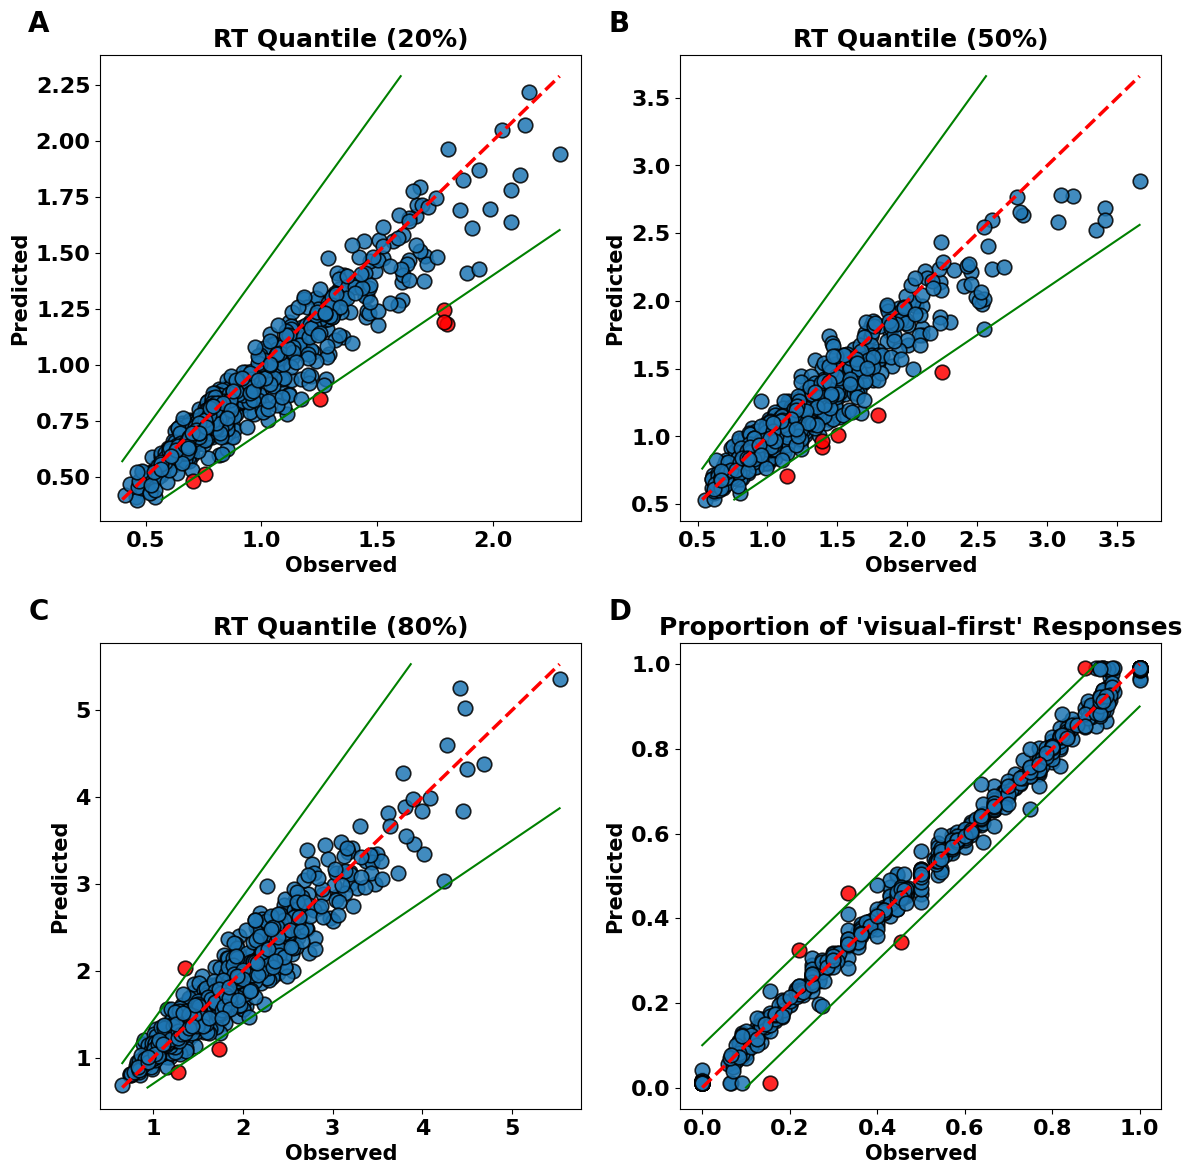

In [19]:
# Configure publication-ready figure formatting parameters
plt.rcParams.update({
    "font.size": 16,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Define diagnostic dimensions (Panel D title updated to reflect accurate psychophysical measure)
plots = [
    (data_['q1'], model_['q1'], "RT Quantile (20%)"),
    (data_['q2'], model_['q2'], "RT Quantile (50%)"),
    (data_['q3'], model_['q3'], "RT Quantile (80%)"),
    (data_['p_vis'], model_['p_vis'], "Proportion of 'visual-first' Responses")
]

panel_labels = ["A", "B", "C", "D"]
R = [r1,r2,r3,r4]
# Iterate over grid cells and plot empirical vs. predicted measures
for i, ax, (x, y, title), label in zip(np.arange(4), axes.flatten(), plots, panel_labels):

    # Render individual participant-SOA data points
    ax.scatter(x[r], y[r],
               s=110,
               edgecolor="black",
               linewidth=1.2,
               alpha=0.85)
    ax.scatter(x[~R[i]], y[~R[i]],
               s=110,
               edgecolor="black",
               c='red',
               linewidth=1.2,
               alpha=0.85)

    # Plot the diagonal line of identity (y = x) representing perfect generative fit
    min_val = min(min(x.dropna()), min(y.dropna()))
    max_val = max(max(x.dropna()), max(y.dropna()))
    ax.plot([min_val, max_val], [min_val, max_val],
            color="red",
            linestyle='--',
            linewidth=2.5)
    if title=="Proportion of 'visual-first' Responses":
        ax.plot([.1, 1], [0, .9],
                color="green",
                linewidth=1.5)
        ax.plot([0, .9], [.1, 1],
                color="green",
                linewidth=1.5)
    else:
        ax.plot([1/.7*min_val, max_val], [min_val, .7*max_val],
                color="green",
                linewidth=1.5)
        ax.plot([min_val, .7*max_val], [1/.7*min_val, max_val],
                color="green",
                linewidth=1.5)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlabel("Observed", fontsize=15)
    ax.set_ylabel("Predicted", fontsize=15)

    # Add panel identification labels (A-D)
    ax.text(-0.15, 1.05, label,
            transform=ax.transAxes,
            fontsize=20,
            fontweight="bold")

plt.tight_layout()

# Save vector PDF for manuscript integration and OSF repository
plt.savefig("figures/TOJ_prior_stimulus_DDMfits.pdf",
            format="pdf",
            bbox_inches="tight")

plt.show()
plt.close()

###############################################################
## 2-3 Cross-Validation

Objective: \
This script executes an out-of-sample predictive cross-validation analysis to evaluate model ability to detect individual differences and generalizability and rule out potential overfitting in the TOJ paradigm. For each unique cell (Participant × Prior Response × SOA), trials are split into independent training (odd-indexed) and testing (even-indexed) subsets. The boundaries represent orthogonal temporal alternatives: Upper (1) for 'visual-first' (v) and Lower (0) for 'auditory-first' (a).Parameters are optimized via MLE on the training subset, and the predictive RT and choice statistics are validated against the held-out empirical testing set.

In [43]:
# split-half the data
current_df = df
current_df['trial_index'] = current_df.groupby(['participant', 'pre_stim', 'SOA']).cumcount()
df_odd = current_df[current_df['trial_index'] % 2 != 0].copy()   # Training Set (Odd trials)
df_even = current_df[current_df['trial_index'] % 2 == 0].copy()  # Testing Set (Even trials)

In [44]:
# fit the model on odd trials and calculate predictive and observed statistics

data_list = []
model_list = []

participants = current_df['participant'].unique()
pre_stims = current_df['pre_stim'].unique()
SOAs = current_df['SOA'].unique()

# Nested loops to isolate each model fitting cell independently
for participant in participants:
    print(participant)
    d_odd_p = df_odd[df_odd['participant'] == participant]
    d_even_p = df_even[df_even['participant'] == participant]
    
    for pre_stim in pre_stims:
        d_odd_pr = d_odd_p[d_odd_p['pre_stim'] == pre_stim]
        d_even_pr = d_even_p[d_even_p['pre_stim'] == pre_stim]
        
        for soa in SOAs:
            d_soa_train = d_odd_pr[d_odd_pr['SOA'] == soa].copy()
            d_soa_test = d_even_pr[d_even_pr['SOA'] == soa].copy()

            model = pyddm.gddm(drift="d", noise="noise", bound=1.0, nondecision='t0', starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},
                               T_dur=d_soa_train['rt'].max() + 0.01)
            
            train_sample = Sample.from_pandas_dataframe(d_soa_train, rt_column_name="rt", choice_column_name="resp_num")
            model.fit(sample=train_sample, verbose=False, lossfunction=LossRobustLikelihood)
            
            
            p_obs = {
                'participant': participant,
                'SOA': soa,
                'pre_stim': pre_stim,
                'q1': d_soa_test['rt'].quantile(.2),
                'q2': d_soa_test['rt'].quantile(.5),
                'q3': d_soa_test['rt'].quantile(.8),
                'p_vis': d_soa_test['resp_num'].mean()
            }
            data_list.append(p_obs)
            s = model.solve()
            p_pred = {
                'participant': participant,
                'SOA': soa,
                'pre_stim': pre_stim,
                'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
                'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
                'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
                'p_vis': s.prob('correct')
            }
            model_list.append(p_pred)
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)

1


Info: Params [-2.51298226  0.34738198  0.6320835   0.83685987] gave -3.118156766910176
Info: Params [-0.63546558  0.53538069 -0.69302291  1.07837746] gave 1.4523883422470605
Info: Params [-0.38406055  0.54078912 -0.62289665  0.91594648] gave 5.947555520124222
Info: Params [ 0.52593349  0.95474696 -0.69904936  1.46821461] gave 4.517460249066249
Info: Params [-0.17775955  0.40120781 -0.77531984  1.32912859] gave 4.974583665343536
Info: Params [-1.2151767   0.22812504  0.44066431  0.03333512] gave 5.65309542610314
Info: Params [-0.90237181  0.69136565  0.79756256  1.41187731] gave 3.1027262815988363
Info: Params [-0.70326692  0.89027935  0.62299077  1.34931679] gave 8.231733372123035
Info: Params [-0.37445634  0.82511235  0.21434163  0.93464616] gave 11.497820131921385
Info: Params [-0.06580784  0.92759224 -0.3555794   1.13138733] gave 10.62017360492959
Info: Params [-0.10172058  0.98916217 -0.31267677  0.76301987] gave 11.00497602948726
Info: Params [ 1.04458288  1.05667779 -0.59070008  

3


Info: Params [-2.31402745  0.63077688  0.24819892  0.82208518] gave -1.8732076816468766
Info: Params [-0.54137243  0.36596748  0.07466531  0.04063075] gave 6.1865272188106335
Info: Params [-0.14782757  1.22987439 -0.34049627  1.04117601] gave 7.129530298803784
Info: Params [-0.60038875  0.8404648   0.13420037  1.87104998] gave 7.709604888414536
Info: Params [-0.13561354  1.4855496   0.38677288  1.998016  ] gave 1.3944617529307475
Info: Params [-0.7401667   0.79415573  0.6815928   0.99249211] gave 10.241015569605867
Info: Params [ 0.78382457  0.85892444 -0.70874351  1.93717598] gave 14.321716070905302
Info: Params [-0.46900328  1.35745723  0.26816368  1.02244648] gave 5.800090748369833
Info: Params [-1.38664766  0.73014114  0.79894898  1.26725955] gave 4.018830472006311
Info: Params [0.07235193 0.77388188 0.33424671 1.57139377] gave 13.0115231610093
Info: Params [-0.29047741  0.81381795  0.56701085  0.97015496] gave 8.761956981056919
Info: Params [-0.2296222   1.02692564 -0.20742819  1.

5


Info: Params [-2.05392342  0.4858184   0.10727393  0.25565223] gave -3.1115482845002975
Info: Params [-2.37369404  0.43714645  0.63169209  0.00623639] gave -2.400020099086839
Info: Params [-0.43902054  1.0046221  -0.79697655  0.66068743] gave -0.5733502355034434
Info: Params [-0.06174406  0.79528634 -0.70800566  0.55679853] gave 7.909834526094484
Info: Params [-0.25460071  0.71691097 -0.79826837  1.23321264] gave 2.7953396815206872
Info: Params [0.20343301 1.30891734 0.21764758 0.82724151] gave 6.153655913212312
Info: Params [-0.49320974  0.84570534  0.7555753   0.90250176] gave 5.759077335025198
Info: Params [5.02562208e-04 6.99058382e-01 6.17005451e-01 9.91678263e-01] gave 7.643079315073006
Info: Params [-1.64590936  1.06699721  0.79946864  1.36248248] gave 4.408663790746435
Info: Params [0.16192002 0.83307777 0.55342926 0.71980449] gave 7.064247954842056
Info: Params [-0.08033154  1.15588958  0.39130592  0.95057957] gave 6.9060316013660845
Info: Params [-0.19808324  0.82311553  0.41

... (26 outputs left out)

21


Info: Params [-0.65053473  0.77471919 -0.61354965  1.13447264] gave 2.466451508450797
Info: Params [ 0.1827386   0.59290872 -0.79706548  1.98924755] gave 7.240313977598902
Info: Params [ 0.34503002  0.82305006 -0.64294129  0.95342446] gave 8.306932613667424
Info: Params [-0.24756017  0.66334013  0.02864153  0.67775172] gave 17.828807579519776
Info: Params [-0.7944664   0.55934985  0.78637755  0.91400737] gave 9.67439366097248
Info: Params [ 0.41193323  0.73729159 -0.79549031  1.35026836] gave 8.236554315438013
Info: Params [ 0.86754892  0.39521457 -0.79940346  0.88877284] gave 3.368661195865289
Info: Params [-0.28559845  0.91353683  0.5748512   1.50289025] gave 7.757298985046824
Info: Params [ 0.04464221  0.68361144 -0.41349941  1.67990014] gave 13.382586441911519
Info: Params [-0.47283926  0.76314288  0.53299644  1.03090593] gave 9.542784398250056
Info: Params [-0.01982839  0.7563164   0.03754638  1.36538866] gave 13.288259653822749
Info: Params [ 0.16360052  0.57105208 -0.60529516  0

22


Info: Params [-3.59022053  0.30459622  0.72672241  0.72151177] gave -0.5873207331506851
Info: Params [-1.41186285  0.66715613 -0.16306507  0.53226043] gave 0.7849106811948401
Info: Params [-0.84734798  1.22452859 -0.34934112  0.74642183] gave 4.693257748506162
Info: Params [ 0.81916123  1.36359259 -0.68403534  0.77463052] gave 4.3003888548811355
Info: Params [ 0.39752181  1.81958759 -0.59050677  1.55526909] gave 0.12944037949383635
Info: Params [-0.38775827  0.47209179 -0.74249048  0.67068295] gave 2.7278341075850854
Info: Params [-1.50885094  1.53208312 -0.13549834  0.59374849] gave 1.8989154059612225
Info: Params [-2.22932063  1.35296531  0.13056664  0.47888498] gave 1.9519999240816117
Info: Params [-0.3210236   1.04368028 -0.50316685  0.75444719] gave 6.515498062789494
Info: Params [-0.88889269  1.22313233 -0.23104031  0.52158013] gave 4.036261321274895
Info: Params [-0.86425362  0.50100821 -0.55428369  0.47058336] gave 0.989724521103793
Info: Params [-1.45521688  1.39790382 -0.0682

In [45]:
model_.to_excel("files/TOJ_prior_stimulus_DDM_crossval_model_.xlsx", index=False)

In [46]:
data_.to_excel("files/TOJ_prior_stimulus_DDM_crossval_data_.xlsx", index=False)

In [49]:
model_ = model_.sort_values(['participant', 'SOA', 'pre_stim']).reset_index(drop=True)

In [50]:
data_ = data_.sort_values(['participant', 'SOA', 'pre_stim']).reset_index(drop=True)

In [52]:
# delete excluded fits
model_ = model_[r].reset_index(drop=True)

In [53]:
data_ = data_[r].reset_index(drop=True)

In [60]:
spearmanr(data_['q1'],model_['q1'])

SignificanceResult(statistic=np.float64(0.7286482805709378), pvalue=np.float64(1.244659350101338e-134))

In [63]:
spearmanr(data_['q2'],model_['q2'])

SignificanceResult(statistic=np.float64(0.6971150752455868), pvalue=np.float64(1.3592935545119088e-118))

In [66]:
spearmanr(data_['q3'],model_['q3'])

SignificanceResult(statistic=np.float64(0.6427128253441081), pvalue=np.float64(2.3835683345847822e-95))

In [69]:
spearmanr(data_['p_vis'],model_['p_vis'])

SignificanceResult(statistic=np.float64(0.7521872690722449), pvalue=np.float64(3.6869430208920225e-148))

###############################################################\
###############################################################
# 3- DDM for general data

In [10]:
df = pd.read_excel("files/TOJ_general_data.xlsx")

In [11]:
df['resp_num'] = df['resp'].map({'v': 1, 'a': 0})

In [12]:
df

,participant,SOA,resp,rt,resp_num
0,1,-400,a,1.788303,0
1,1,-400,a,1.537577,0
2,1,-400,a,1.554352,0
3,1,-400,a,1.353832,0
4,1,-400,a,1.504235,0
...,...,...,...,...,...
12013,22,400,v,0.602115,1
12014,22,400,v,0.852639,1
12015,22,400,v,0.568502,1
12016,22,400,v,0.802461,1


In [5]:
# DataFrame to accumulate the final fitted DDM parameters across participants and SOAs
params = pd.DataFrame()

# Extract the list of unique participant identifiers
participants = df['participant'].unique()

# Extract unique Stimulus Onset Asynchronies (SOAs) present in this participant's profile
SOAs = df['SOA'].unique()

# Iterate through each individual participant to perform subject-level fitting
for participant in participants:
    print(participant)
    # Isolate data for the current participant
    d = df[df['participant'] == participant]

    # Loop through each distinct SOA to fit independent psychophysical profiles
    for soa in SOAs:
        # Filter the dataset for the specific Participant x SOA cell
        d_soa = d[d['SOA'] == soa]


        # Configure Generalized DDM architecture with a dynamic noise scaling parameter 
        # and a fixed boundary constraint set to 1.0 (scaling assumption)
        model = pyddm.gddm(drift="d",
                           noise="noise",  # Noise treated as a free fitting parameter
                           bound=1.0,      # Fixed decision boundary at 1.0
                           nondecision='t0', 
                           starting_position="x0",
                           parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # Free parameter search spaces
                           T_dur=d_soa['rt'].max() + 0.01)

        # Structure the target data subset into a specialized PyDDM Sample object
        data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

        # Execute maximum likelihood optimization routine to fit the model to the sample data
        model.fit(sample=data, lossfunction=LossRobustLikelihood, verbose=False)

        # Extract the optimized free parameter estimates from the converged model instance
        p = model.parameters()

        # Construct a single-row DataFrame containing parameter estimates for the current condition
        pp = pd.DataFrame({
            'participant': [participant],
            'SOA': [soa],
            'drift': [p['drift']['drift']],
            'noise': [p['noise']['noise']],  # Store the dynamic estimated noise variance
            'bound': [1.0],  # Document the fixed boundary constraint
            'Z': [p['IC']['x0']],
            't0': [p['overlay']['nondectime']]
        })

        # Append the calculated metrics row into the cumulative parameter matrix
        params = pd.concat([params, pp], ignore_index=True)


1


Info: Params [-1.15142604  0.28564399  0.55945305  0.26483695] gave 10.17320342327702
Info: Params [-0.78896858  0.18604798  0.14855868  0.00364616] gave 13.057466872367424
Info: Params [-0.78755547  0.80131061  0.01184037  0.71232565] gave 35.41628227881532
Info: Params [-0.12852671  0.8809405  -0.2432669   0.7679939 ] gave 46.59315251989847
Info: Params [ 0.19794535  0.8829338  -0.07207161  0.80850798] gave 52.412523054907794
Info: Params [-0.18417985  0.93249184 -0.03607788  0.71617959] gave 49.98100170234018
Info: Params [ 0.53155727  0.75491695 -0.40854498  0.65174002] gave 49.81607529339739
Info: Params [-0.06949931  0.73901471 -0.12339969  0.57777061] gave 60.433364195117264
Info: Params [ 0.07213486  0.7714755  -0.24690333  0.6028091 ] gave 60.26770573933083
Info: Params [ 0.27050277  0.86136454 -0.34229281  1.09606568] gave 49.28492822925207
Info: Params [ 0.14587087  0.93623571 -0.3242827   0.79802952] gave 47.703872027150695
Info: Params [ 0.65164168  1.03914798 -0.26409406 

3


Info: Params [-1.41653434  0.33790306  0.16641704  0.53260825] gave -4.1716604759915095
Info: Params [-0.97473241  0.72957499 -0.0790214   0.7733702 ] gave 24.098704140658334
Info: Params [-0.87410358  1.09616805 -0.02609593  0.93139337] gave 30.941622767673746
Info: Params [-0.32487171  0.84484439 -0.24997236  0.93678059] gave 44.42584834933382
Info: Params [-0.29177473  0.9284696   0.14857011  0.9118157 ] gave 48.54562192223857
Info: Params [-0.46013775  0.851988    0.37690829  0.95247238] gave 45.09113928066827
Info: Params [-0.30442139  0.81689299  0.15125083  0.98688755] gave 60.545969346260925
Info: Params [-0.64652256  0.95765774  0.34797368  1.00758605] gave 42.87725497132844
Info: Params [-0.08287908  0.81028058  0.24976116  0.8138713 ] gave 55.53135836934835
Info: Params [0.02835936 0.77637629 0.16412466 0.99406062] gave 61.66037166966376
Info: Params [0.32158526 0.7583893  0.04550251 0.83249334] gave 52.92267581022999
Info: Params [ 0.04783815  1.02774957 -0.11824053  1.2291

5


Info: Params [-2.02258518e+00  3.69075772e-01  6.79890077e-01  1.34470009e-03] gave -11.655850308164759
Info: Params [-2.37432696  0.91026237  0.3375271   0.34186686] gave 2.4851838472936127
Info: Params [-1.16015148  1.07754601 -0.1887584   0.48797658] gave 18.020544620881957
Info: Params [-0.52668684  0.92739894 -0.3158556   0.51819938] gave 33.04663574925412
Info: Params [ 0.1205758   1.02487278 -0.14213159  0.6380318 ] gave 45.435310542995126
Info: Params [0.13681014 1.06262161 0.03646035 0.77334533] gave 45.17315260095614
Info: Params [0.02287205 0.81478721 0.24822251 0.45222237] gave 52.84448100028689
Info: Params [ 0.26652846  0.88784211 -0.00445904  0.55165621] gave 49.779369141491145
Info: Params [-0.20089323  0.89019932  0.45572804  0.62049612] gave 50.17369807078223
Info: Params [0.33332838 0.88740697 0.20730959 0.40635872] gave 43.01024096556779
Info: Params [0.27031887 0.8739242  0.1507422  0.36153618] gave 45.73152750459802
Info: Params [0.08619864 1.04711537 0.20392277 0

... (152 outputs left out)

Info: Params [-0.85224906  1.27283588  0.34079028  0.69129994] gave 27.136706554291088
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-1.01805968  0.38888928 -0.27766045  0.53140512] gave 4.78254698612861
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice f

Info: Params [-0.05670048  0.71966351  0.10186312  0.65056138] gave 61.33388891511943
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-0.02612458  0.77317562 -0.24551072  0.82758944] gave 54.73985566957064
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice f

Info: Params [ 0.32926619  0.71513073 -0.03521346  0.56267608] gave 58.06680823615976
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [0.5167227  0.64883487 0.0824873  0.40460045] gave 44.26314183554422
C:\Users\sajjad\AppData\Local\Temp\ipykernel_46456\1129151476.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from 

     participant  SOA     drift     noise  bound         Z        t0
0              2   40  0.241133  0.945007    1.0  0.209147  0.301905
1              2  200  0.878088  1.026802    1.0  0.015901  0.325204
2              2  -80  0.661701  0.962117    1.0 -0.290576  0.302134
3              2  120 -0.343774  1.100126    1.0  0.622668  0.651879
4              2  100  0.129980  0.980330    1.0  0.283532  0.300555
..           ...  ...       ...       ...    ...       ...       ...
455           21    0 -0.160233  0.622396    1.0  0.092724  0.567563
456           21  300  0.241329  0.768221    1.0  0.447592  0.790601
457           21  100  0.329266  0.715131    1.0 -0.035213  0.562676
458           21  250  0.516723  0.648835    1.0  0.082487  0.404600
459           21  150  0.499548  0.679364    1.0  0.023424  0.733086

[460 rows x 7 columns]


In [6]:
# save parameters
params.to_excel("files/TOJ_general_DDM_parameters.xlsx", index=False)